# Week 2: EI candidate suggestions with Matérn 3/2

Generate one unevaluated candidate per function using Expected Improvement with the Matérn 3/2 kernel, across Functions 1–8. Function 3 is included as a previously tested case. The notebook records each candidate, posterior mean, and posterior standard deviation; it does not evaluate objectives or save predictions. These candidates feed the submission table in section 9.

Matérn 3/2 is the single kernel used here. The choice rests on held-out cross-validation in Notebook 04, with the caveats recorded there.

## 1. Import Libraries and Define XI_VALUES

In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

from bayesian_bbo import (
    CONFIG,
    FUNCTION_SPECS,
    BayesianOptimizer,
    OptimisationConfig,
    format_submission,
    load_observations,
)

FUNCTION_IDS = tuple(FUNCTION_SPECS)
XI_VALUES = {
    1: 0.00010366701219489613,
    2: 0.02169598518452902,
    3: 0.008514510271522311,
    4: 0.7327808565722272,
    5: 35.75969037053485,
    6: 0.046625804381253966,
    7: 0.03342741263225186,
    8: 0.09678071263663912,
}


## 2. Define LENGTH_CAPS and Kernel Factory Registry

`LENGTH_CAPS` is defined in this section. `XI_VALUES` is hardcoded in section 1; each entry equals 0.1 times the standard deviation of that function's observed outputs (the same `selected_alpha` as Notebook 05). The Matérn 3/2 kernel factory uses ARD length scales with a lower bound of `1e-3`, the function-specific cap as upper bound, and the same amplitude and white-noise components. The registry holds only this kernel.

In [26]:
LENGTH_CAPS = {
    1: 31.622776601683793,
    2: 31.622776601683793,
    3: 31.622776601683793,
    4: 10.0,
    5: 100.0,
    6: 31.622776601683793,
    7: 31.622776601683793,
    8: 100.0,
}


def make_matern_32_kernel(dimension, length_cap):
    return (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(
            length_scale=np.ones(dimension),
            length_scale_bounds=(1e-3, length_cap),
            nu=1.5,
        )
        + WhiteKernel(1e-5, (1e-8, 1e1))
    )


kernel_factories = {
    "Matérn 3/2": make_matern_32_kernel,
}


## 3. Register Function Metadata and Search Spaces

Function metadata comes from `FUNCTION_SPECS`. The objective evaluator is external, so the notebook uses observed data and the common per-coordinate `[0, 1)` search domain; it does not call an objective function.

In [27]:
data_candidates = [Path("../../data"), Path("data"), Path("../data")]
data_root = next(
    (path.resolve() for path in data_candidates if (path / "function_1").is_dir()),
    None,
)
if data_root is None:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")

observations_by_function = {
    function_id: load_observations(data_root, function_id)
    for function_id in FUNCTION_IDS
}
function_registry = {
    function_id: {
        "function_name": f"Function {function_id}",
        "dimension": FUNCTION_SPECS[function_id],
        "bounds": [(0.0, 1.0)] * FUNCTION_SPECS[function_id],
        "observation_count": len(observations_by_function[function_id].inputs),
    }
    for function_id in FUNCTION_IDS
}

assert set(LENGTH_CAPS) == set(FUNCTION_IDS)
assert all(
    observations_by_function[function_id].dimension == function_registry[function_id]["dimension"]
    for function_id in FUNCTION_IDS
)
print(f"Data root: {data_root}")
pd.DataFrame.from_dict(function_registry, orient="index").drop(columns="bounds")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


,function_name,dimension,observation_count
1,Function 1,2,11
2,Function 2,2,11
3,Function 3,3,16
4,Function 4,4,31
5,Function 5,4,21
6,Function 6,5,21
7,Function 7,6,31
8,Function 8,8,41


## 4. Create Optimizer with EI Acquisition

Each function/kernel pair gets a fresh optimizer with a one-suggestion budget. EI uses that function's selected `xi` from `XI_VALUES`; its incumbent defaults to the best measured output in that function's observations.

In [28]:
ACQUISITION = "ei"


def create_optimizer(observations, kernel, xi):
    return BayesianOptimizer(
        observations,
        OptimisationConfig(
            budget=1,
            acquisition=ACQUISITION,
            xi=xi,
            seed=CONFIG["random_state"],
            kernel=kernel,
        ),
    )

## 5–6. Iterate and Capture Candidate Predictions

The loop proposes one point for each function using the Matérn 3/2 kernel factory and that function's selected `xi`. `suggest_with_prediction()` returns the selected point and the GP posterior mean and standard deviation at that point.

In [29]:
suggestion_records = []
for function_id, function_info in function_registry.items():
    observations = observations_by_function[function_id]
    dimension = function_info["dimension"]
    length_cap = LENGTH_CAPS[function_id]
    xi = XI_VALUES[function_id]
    for kernel_name, kernel_factory in kernel_factories.items():
        kernel = kernel_factory(dimension, length_cap)
        optimizer = create_optimizer(observations, kernel, xi)
        point, mean, std = optimizer.suggest_with_prediction()
        suggestion_records.append({
            "function_id": function_id,
            "function": function_info["function_name"],
            "dimension": dimension,
            "kernel": kernel_name,
            "iteration": 1,
            "random_state": CONFIG["random_state"],
            "acquisition": ACQUISITION,
            "xi": xi,
            "length_cap": length_cap,
            "point": point.tolist(),
            "formatted_point": format_submission(point),
            "mean": mean,
            "std": std,
        })
suggestion_records[:2]

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit a

[{'function_id': 1,
  'function': 'Function 1',
  'dimension': 2,
  'kernel': 'Matérn 3/2',
  'iteration': 1,
  'random_state': 42,
  'acquisition': 'ei',
  'xi': 0.00010366701219489613,
  'length_cap': 31.622776601683793,
  'point': [0.7021, 0.165487],
  'formatted_point': '0.702100-0.165487',
  'mean': 0.00014133958446040519,
  'std': 0.0008480974766431138},
 {'function_id': 2,
  'function': 'Function 2',
  'dimension': 2,
  'kernel': 'Matérn 3/2',
  'iteration': 1,
  'random_state': 42,
  'acquisition': 'ei',
  'xi': 0.02169598518452902,
  'length_cap': 31.622776601683793,
  'point': [0.689383, 0.099113],
  'formatted_point': '0.689383-0.099113',
  'mean': 0.6081337688615129,
  'std': 0.056081117691020664}]

## 7. Aggregate Results into a DataFrame

In [30]:
suggestion_results = pd.DataFrame(suggestion_records).sort_values(
    ["function_id", "kernel"]
).reset_index(drop=True)
suggestion_results

,function_id,function,dimension,kernel,iteration,random_state,acquisition,xi,length_cap,point,formatted_point,mean,std
0,1,Function 1,2,Matérn 3/2,1,42,ei,0.000104,31.622777,"[0.7021, 0.165487]",0.702100-0.165487,0.000141,0.000848
1,2,Function 2,2,Matérn 3/2,1,42,ei,0.021696,31.622777,"[0.689383, 0.099113]",0.689383-0.099113,0.608134,0.056081
2,3,Function 3,3,Matérn 3/2,1,42,ei,0.008515,31.622777,"[0.292059, 0.194387, 0.490197]",0.292059-0.194387-0.490197,0.000256,0.065249
3,4,Function 4,4,Matérn 3/2,1,42,ei,0.732781,10.000000,"[0.358431, 0.52023, 0.428009, 0.407961]",0.358431-0.520230-0.428009-0.407961,-2.893219,1.157735
4,5,Function 5,4,Matérn 3/2,1,42,ei,35.759690,100.000000,"[0.421782, 0.48008, 0.974874, 0.997647]",0.421782-0.480080-0.974874-0.997647,1720.386794,71.126598
5,6,Function 6,5,Matérn 3/2,1,42,ei,0.046626,31.622777,"[0.50831, 0.364919, 0.501744, 0.958429, 0.07661]",0.508310-0.364919-0.501744-0.958429-0.076610,-0.447812,0.214298
6,7,Function 7,6,Matérn 3/2,1,42,ei,0.033427,31.622777,"[0.038283, 0.116645, 0.103052, 0.287496, 0.333...",0.038283-0.116645-0.103052-0.287496-0.333062-0...,1.084241,0.191096
7,8,Function 8,8,Matérn 3/2,1,42,ei,0.096781,100.000000,"[0.07949, 0.193771, 0.285174, 0.184983, 0.7237...",0.079490-0.193771-0.285174-0.184983-0.723741-0...,9.880347,0.126572


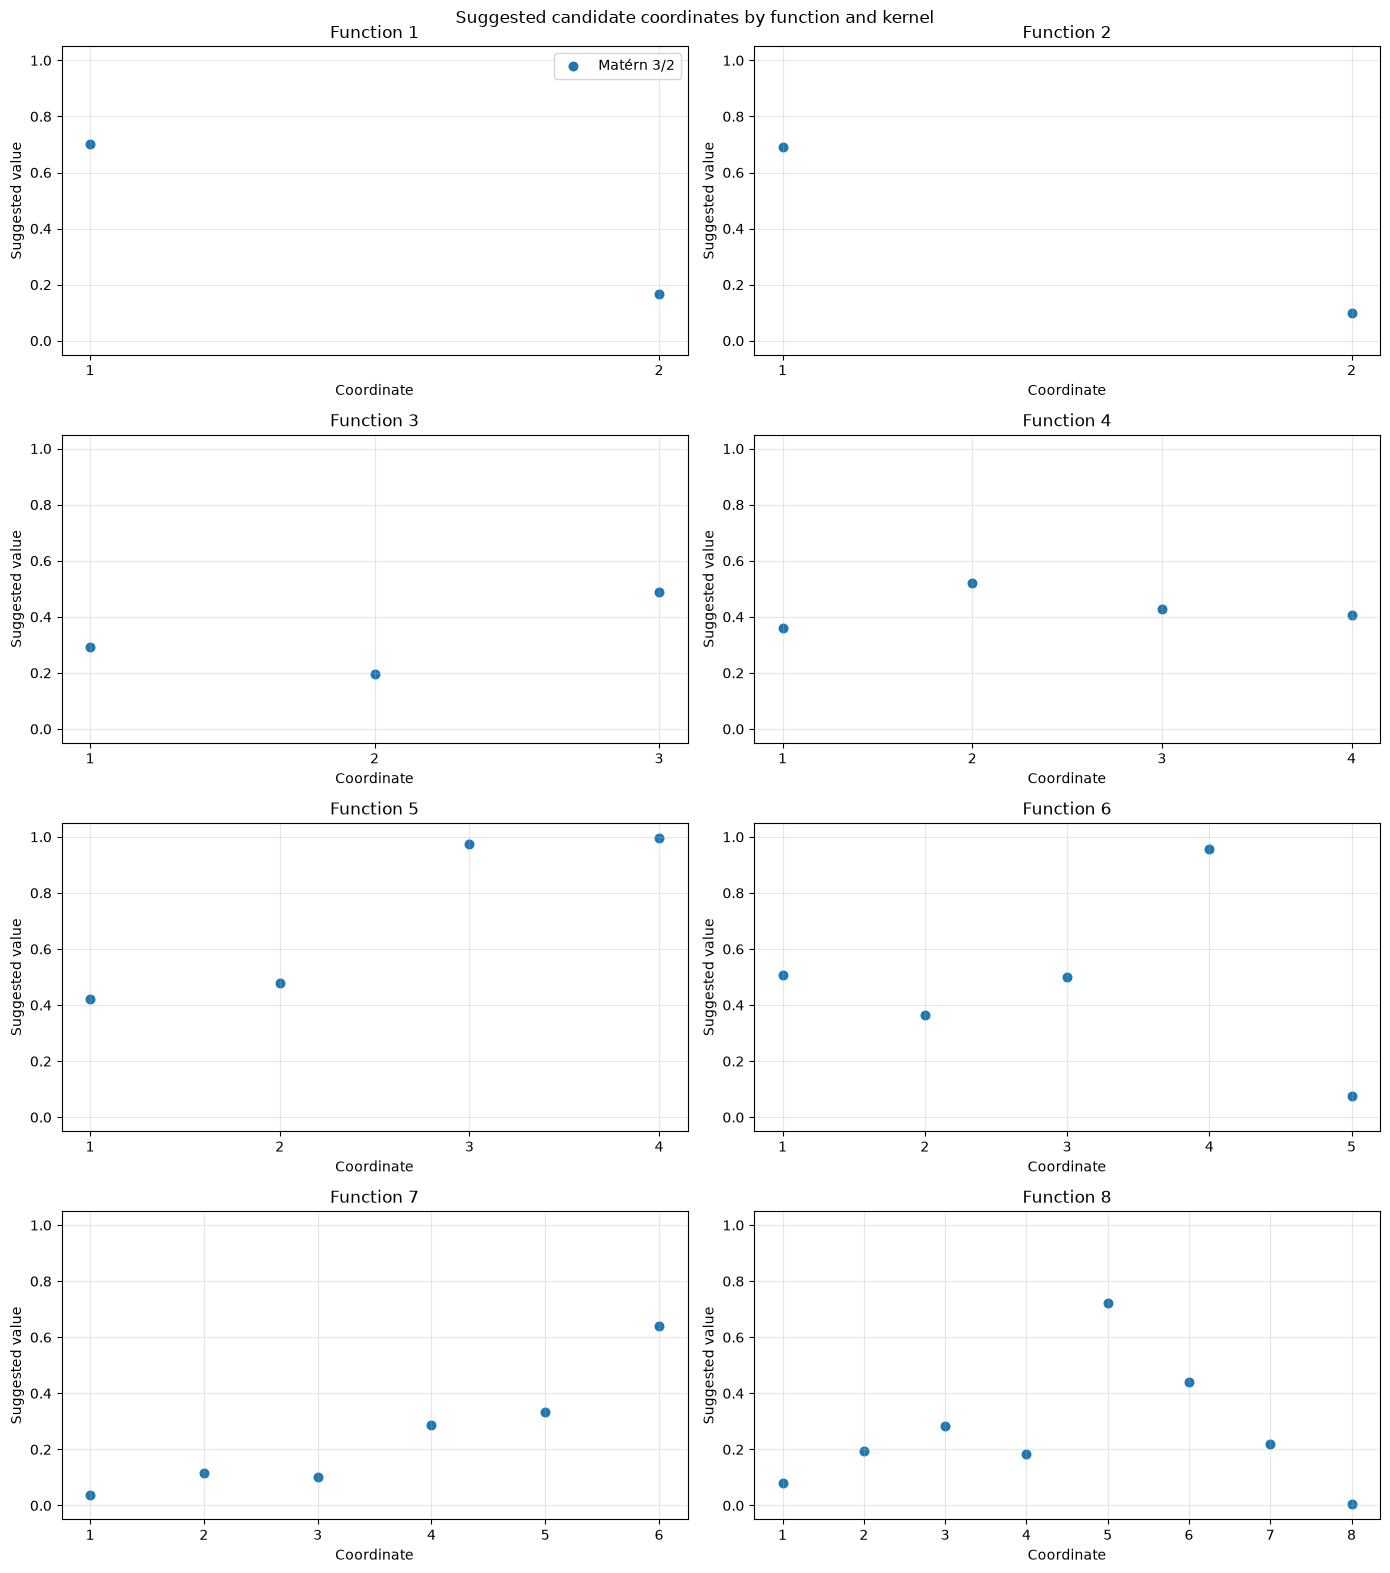

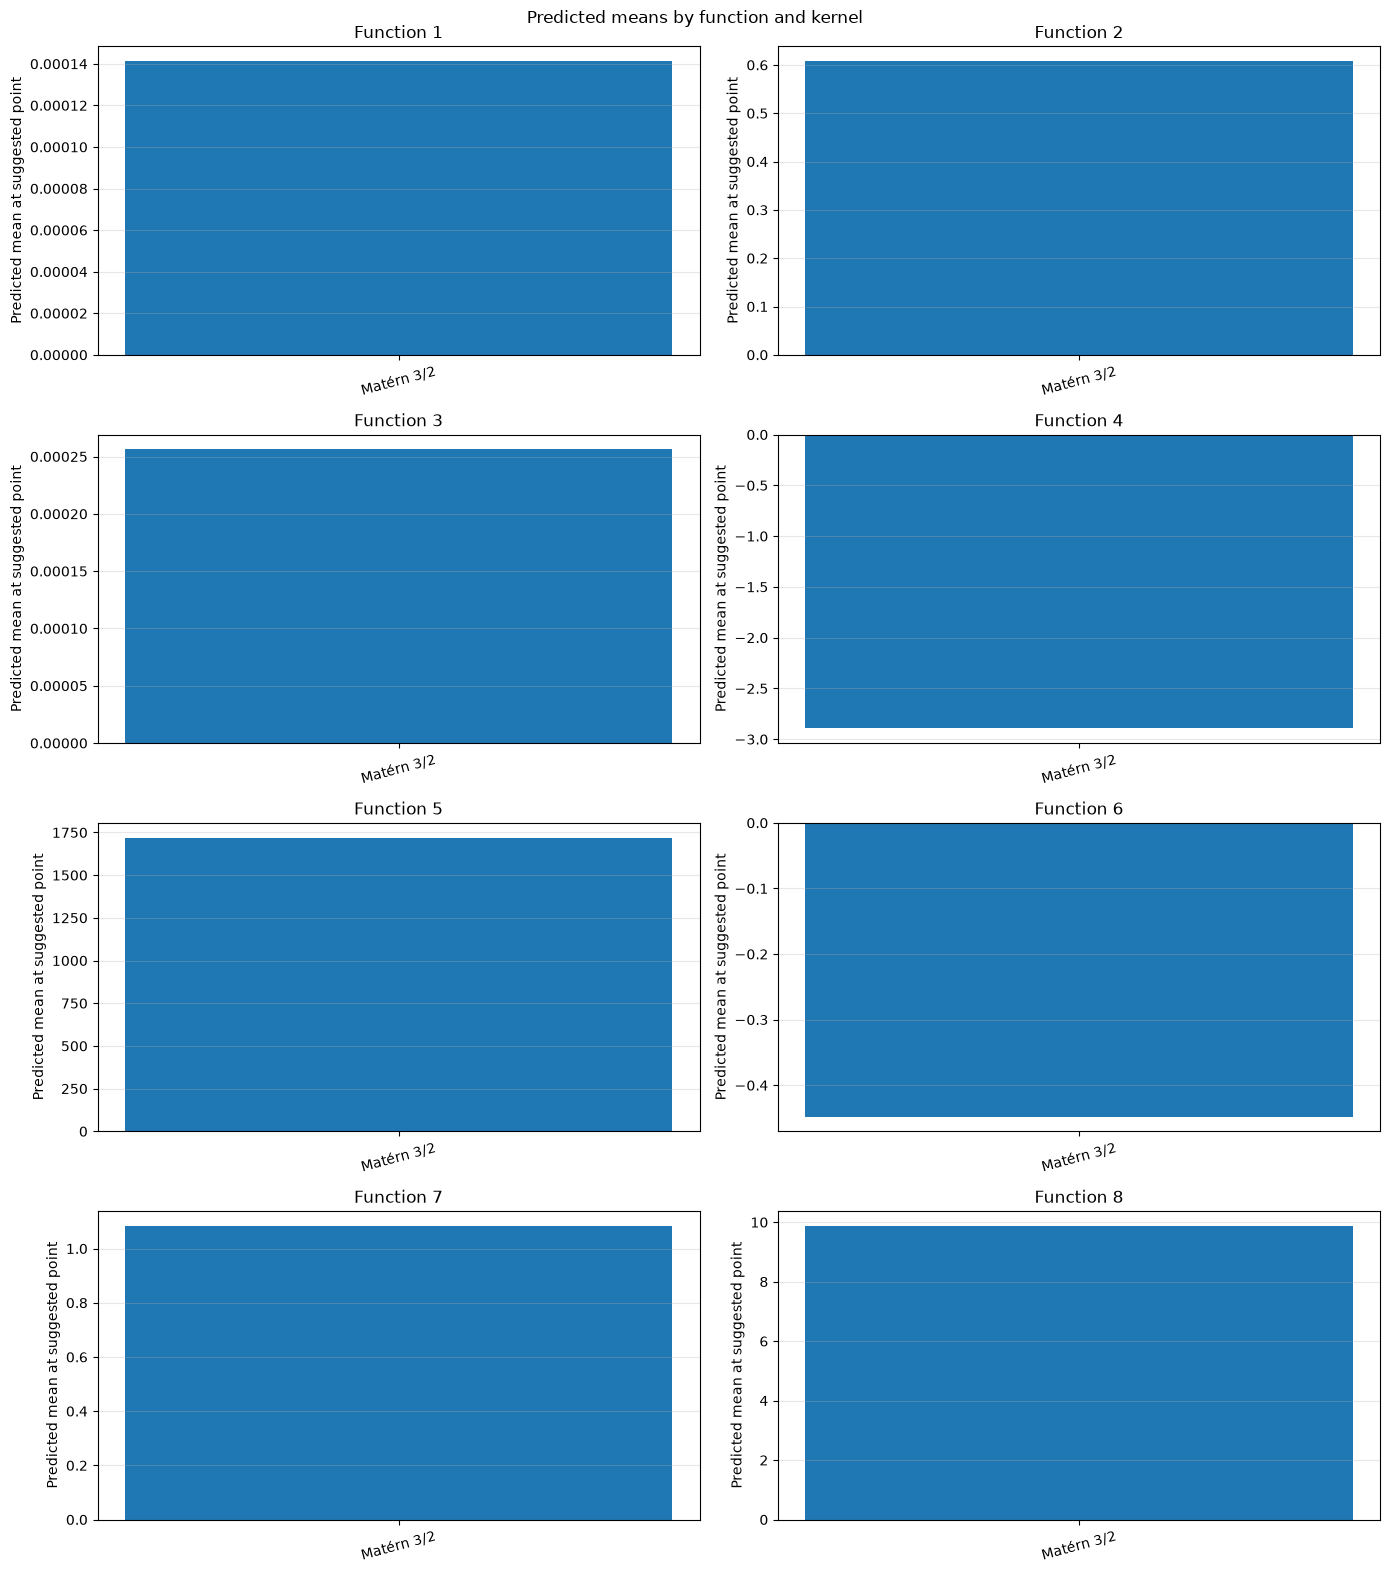

In [31]:
kernel_names = list(kernel_factories)
kernel_colors = dict(
    zip(kernel_names, plt.rcParams["axes.prop_cycle"].by_key()["color"])
)

point_figure, point_axes = plt.subplots(4, 2, figsize=(14, 16))
for function_id, ax in zip(FUNCTION_IDS, point_axes.ravel()):
    function_rows = suggestion_results[
        suggestion_results["function_id"] == function_id
    ]
    for kernel_index, kernel_name in enumerate(kernel_names):
        row = function_rows[function_rows["kernel"] == kernel_name].iloc[0]
        coordinates = np.asarray(row["point"])
        coordinate_positions = np.arange(1, len(coordinates) + 1, dtype=float)
        coordinate_positions += (
            kernel_index - (len(kernel_names) - 1) / 2
        ) * 0.12
        ax.scatter(
            coordinate_positions,
            coordinates,
            color=kernel_colors[kernel_name],
            label=kernel_name,
            s=38,
        )
    ax.set_title(f"Function {function_id}")
    ax.set_xlabel("Coordinate")
    ax.set_ylabel("Suggested value")
    ax.set_ylim(-0.05, 1.05)
    ax.set_xticks(np.arange(1, FUNCTION_SPECS[function_id] + 1))
    ax.grid(True, alpha=0.3)
point_axes[0, 0].legend()
point_figure.suptitle("Suggested candidate coordinates by function and kernel")
point_figure.tight_layout()
plt.show()

mean_figure, mean_axes = plt.subplots(4, 2, figsize=(14, 16))
for function_id, ax in zip(FUNCTION_IDS, mean_axes.ravel()):
    function_rows = suggestion_results[
        suggestion_results["function_id"] == function_id
    ]
    means = [
        function_rows.loc[function_rows["kernel"] == kernel_name, "mean"].iloc[0]
        for kernel_name in kernel_names
    ]
    ax.bar(
        kernel_names,
        means,
        color=[kernel_colors[kernel_name] for kernel_name in kernel_names],
    )
    ax.set_title(f"Function {function_id}")
    ax.set_ylabel("Predicted mean at suggested point")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(True, axis="y", alpha=0.3)
mean_figure.suptitle("Predicted means by function and kernel")
mean_figure.tight_layout()
plt.show()

## 8. Validate and Inspect Suggestions

In [32]:
assert ACQUISITION == "ei"
assert set(kernel_factories) == {"Matérn 3/2"}
assert tuple(FUNCTION_SPECS) == FUNCTION_IDS
assert set(LENGTH_CAPS) == set(FUNCTION_IDS)
assert set(XI_VALUES) == set(FUNCTION_IDS)
assert len(suggestion_results) == len(FUNCTION_IDS) * len(kernel_factories)
assert np.isfinite(suggestion_results["mean"]).all()
assert np.isfinite(suggestion_results["std"]).all()
assert (suggestion_results["std"] >= 0).all()
assert all(
    row.xi == XI_VALUES[row.function_id]
    for row in suggestion_results.itertuples()
)
assert all(
    len(row.point) == row.dimension
    and all(0.0 <= coordinate < 1.0 for coordinate in row.point)
    for row in suggestion_results.itertuples()
)

print("Candidate preview")
display(suggestion_results.head())
print("Suggestion count by function and kernel")
display(
    suggestion_results.groupby(["function", "kernel"])
    .size()
    .rename("suggestions")
    .to_frame()
)


Candidate preview


,function_id,function,dimension,kernel,iteration,random_state,acquisition,xi,length_cap,point,formatted_point,mean,std
0,1,Function 1,2,Matérn 3/2,1,42,ei,0.000104,31.622777,"[0.7021, 0.165487]",0.702100-0.165487,0.000141,0.000848
1,2,Function 2,2,Matérn 3/2,1,42,ei,0.021696,31.622777,"[0.689383, 0.099113]",0.689383-0.099113,0.608134,0.056081
2,3,Function 3,3,Matérn 3/2,1,42,ei,0.008515,31.622777,"[0.292059, 0.194387, 0.490197]",0.292059-0.194387-0.490197,0.000256,0.065249
3,4,Function 4,4,Matérn 3/2,1,42,ei,0.732781,10.000000,"[0.358431, 0.52023, 0.428009, 0.407961]",0.358431-0.520230-0.428009-0.407961,-2.893219,1.157735
4,5,Function 5,4,Matérn 3/2,1,42,ei,35.759690,100.000000,"[0.421782, 0.48008, 0.974874, 0.997647]",0.421782-0.480080-0.974874-0.997647,1720.386794,71.126598


Suggestion count by function and kernel


,,suggestions
function,kernel,
Function 1,Matérn 3/2,1
Function 2,Matérn 3/2,1
Function 3,Matérn 3/2,1
Function 4,Matérn 3/2,1
Function 5,Matérn 3/2,1
Function 6,Matérn 3/2,1
Function 7,Matérn 3/2,1
Function 8,Matérn 3/2,1


## 9. Matérn 3/2 Suggestions in Submission Format

The table below contains one Matérn 3/2 candidate for each function, formatted with the repository's six-decimal submission convention.

In [33]:
matern_32_submission_points = (
    suggestion_results.loc[
        suggestion_results["kernel"] == "Matérn 3/2",
        ["function_id", "formatted_point"],
    ]
    .rename(columns={"formatted_point": "submission"})
    .sort_values("function_id")
    .reset_index(drop=True)
)

assert matern_32_submission_points["function_id"].tolist() == list(FUNCTION_IDS)
matern_32_submission_points


,function_id,submission
0,1,0.702100-0.165487
1,2,0.689383-0.099113
2,3,0.292059-0.194387-0.490197
3,4,0.358431-0.520230-0.428009-0.407961
4,5,0.421782-0.480080-0.974874-0.997647
5,6,0.508310-0.364919-0.501744-0.958429-0.076610
6,7,0.038283-0.116645-0.103052-0.287496-0.333062-0...
7,8,0.079490-0.193771-0.285174-0.184983-0.723741-0...
